# Student Stress: DAGs, BIC comparison, and causal effects (DoWhy)

**Outcome:** `stress_level` (0 = low, 1 = medium, 2 = high)  
**Causes:** `study_load`, `noise_level`, `living_conditions`, `academic_performance`, `future_career_concerns`

In [1]:
# !pip install dowhy statsmodels
# %pip install dowhy econml xgboost scikit-learn statsmodels networkx matplotlib pandas numpy
%pip install "numpy<2.2" dowhy econml # xgboost scikit-learn statsmodels networkx matplotlib pandas
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import statsmodels.api as sm
from dowhy import CausalModel, gcm
import warnings
warnings.filterwarnings('ignore')


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Load data

In [2]:
from pathlib import Path
CSV_PATH = Path.home() / 'Downloads' / 'archive (4)' / 'StressLevelDataset.csv'
print('File found:', CSV_PATH.exists())
stress = pd.read_csv(CSV_PATH)

CAUSES = ['study_load', 'noise_level', 'living_conditions',
          'academic_performance', 'future_career_concerns']
OUTCOME = 'stress_level'

print(stress.shape)
stress[CAUSES + [OUTCOME]].head()

File found: True
(1100, 21)


,study_load,noise_level,living_conditions,academic_performance,future_career_concerns,stress_level
0,2,2,3,3,3,1
1,4,3,1,1,5,2
2,3,2,2,2,2,1
3,4,4,2,2,4,2
4,3,3,2,4,2,1


## 2. Candidate DAGs

DAG1 and DAG2 are OG original. DAG3 and DAG4 are alternates for further comparisons.

In [3]:
dags = {
    # --- My DAGs ---
    'DAG1': [
        ('safety', 'stress_level'),
        ('study_load', 'stress_level'),
        ('future_career_concerns', 'stress_level'),
        ('noise_level', 'stress_level'),
        ('mental_health_history', 'stress_level'),
    ],
    'DAG2': [
        ('safety', 'stress_level'),
        ('living_conditions', 'noise_level'),
        ('noise_level', 'stress_level'),
        ('mental_health_history', 'stress_level'),
    ],
    # --- Additional alternatives ---
    'DAG3_academic_pathway': [
        ('study_load', 'academic_performance'),
        ('academic_performance', 'future_career_concerns'),
        ('future_career_concerns', 'stress_level'),
        ('study_load', 'stress_level'),
        ('mental_health_history', 'stress_level'),
    ],
    'DAG4_combined': [
        ('safety', 'stress_level'),
        ('mental_health_history', 'stress_level'),
        ('study_load', 'stress_level'),
        ('noise_level', 'stress_level'),
        ('future_career_concerns', 'stress_level'),
        ('living_conditions', 'noise_level'),
        ('living_conditions', 'academic_performance'),
        ('study_load', 'academic_performance'),
        ('academic_performance', 'future_career_concerns'),
    ],
}

# Each DAG contains ONLY the variables in its edges - no floating nodes
graphs = {name: nx.DiGraph(edges) for name, edges in dags.items()}
for name, g in graphs.items():
    assert nx.is_directed_acyclic_graph(g), name

all_nodes = sorted(set().union(*[g.nodes for g in graphs.values()]))
data = stress[all_nodes].copy()
print('Nodes:', all_nodes)


Nodes: ['academic_performance', 'future_career_concerns', 'living_conditions', 'mental_health_history', 'noise_level', 'safety', 'stress_level', 'study_load']


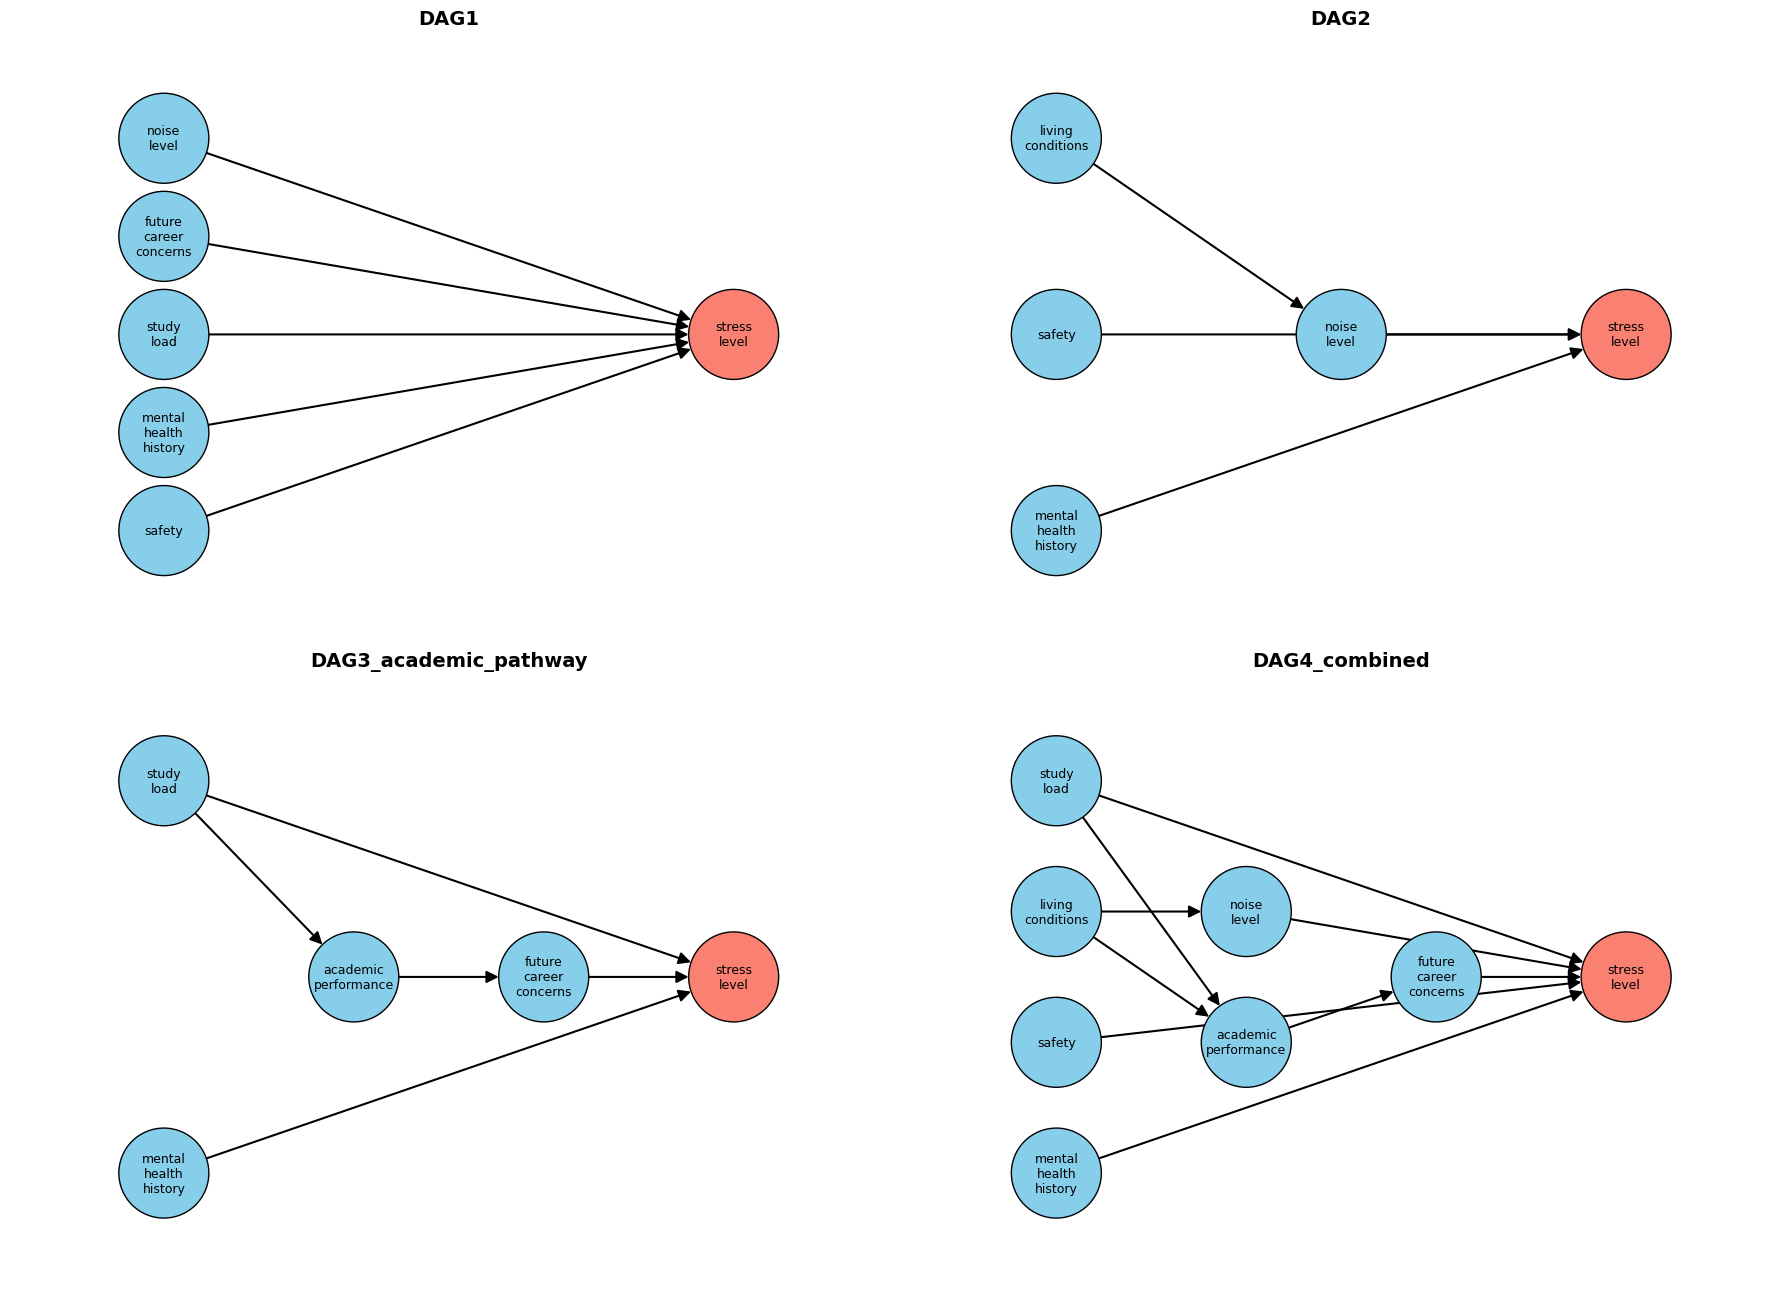

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(18, 13))
for ax, (name, g) in zip(axes.ravel(), graphs.items()):
    # layer = length of longest path from a root node (works in any networkx version)
    for n in nx.topological_sort(g):
        preds = list(g.predecessors(n))
        g.nodes[n]['layer'] = 0 if not preds else max(g.nodes[p]['layer'] for p in preds) + 1
    pos = nx.multipartite_layout(g, subset_key='layer')
    colors = ['salmon' if n == OUTCOME else 'skyblue' for n in g]
    nx.draw_networkx_nodes(g, pos, ax=ax, node_size=4200, node_color=colors, edgecolors='black')
    nx.draw_networkx_labels(g, pos, ax=ax, labels={n: n.replace('_', '\n') for n in g}, font_size=9)
    nx.draw_networkx_edges(g, pos, ax=ax, node_size=4200, arrowstyle='-|>', arrowsize=18, width=1.5)
    ax.set_title(name, fontsize=14, fontweight='bold')
    ax.margins(0.2)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Compare DAGs with BIC

A DAG's likelihood factorises into each node given its parents, so DAG BIC = sum of BIC(node ~ parents).  
BIC = −2·logL + k·ln(n). **Lower is better**; ΔBIC > 10 is very strong evidence for the better DAG.

In [5]:
def node_bic(df, node, parents):
    y = df[node].astype(float)
    X = sm.add_constant(df[parents].astype(float), has_constant='add') if parents \
        else np.ones((len(df), 1))
    return sm.OLS(y, X).fit().bic

def dag_bic(df, g):
    # Nodes in the DAG: scored given their parents.
    # Variables not in this DAG: scored as independent, so every DAG is scored on the same data.
    in_dag = sum(node_bic(df, n, list(g.predecessors(n))) for n in g.nodes)
    not_in_dag = sum(node_bic(df, n, []) for n in all_nodes if n not in g)
    return in_dag + not_in_dag

bic_table = pd.DataFrame({
    'DAG': list(graphs),
    'edges': [g.number_of_edges() for g in graphs.values()],
    'BIC': [dag_bic(data, g) for g in graphs.values()],
}).sort_values('BIC').reset_index(drop=True)
bic_table['delta_BIC'] = bic_table['BIC'] - bic_table['BIC'].min()
print(bic_table.to_string(index=False))

best = bic_table.loc[0, 'DAG']
best_graph = graphs[best]
print('\nBest DAG:', best)
print('Edges:', list(best_graph.edges()))

                  DAG  edges          BIC   delta_BIC
        DAG4_combined      9 24298.884434    0.000000
DAG3_academic_pathway      5 24946.442761  647.558327
                 DAG2      4 25568.815541 1269.931107
                 DAG1      5 25615.237184 1316.352750

Best DAG: DAG4_combined
Edges: [('safety', 'stress_level'), ('mental_health_history', 'stress_level'), ('study_load', 'stress_level'), ('study_load', 'academic_performance'), ('noise_level', 'stress_level'), ('future_career_concerns', 'stress_level'), ('living_conditions', 'noise_level'), ('living_conditions', 'academic_performance'), ('academic_performance', 'future_career_concerns')]


## 4. Is each causal effect identified? (DoWhy)

In [6]:
estimands = {}
for cause in CAUSES:
    if cause not in best_graph or not nx.has_path(best_graph, cause, OUTCOME):
        print(f'\n========== {cause} -> {OUTCOME} ==========')
        print(f'No directed path from {cause} to {OUTCOME} in {best}: '
              'the DAG assumes no causal effect, so there is nothing to identify.')
        continue
    model = CausalModel(data=data, graph=best_graph, treatment=cause, outcome=OUTCOME)
    estimand = model.identify_effect()
    estimands[cause] = (model, estimand)
    print(f'\n========== {cause} -> {OUTCOME} ==========')
    print(estimand)


========== study_load -> stress_level ==========
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
      d                      
─────────────(E[stressₗₑᵥₑₗ])
d[study_load]                
Estimand assumption 1, Unconfoundedness: If U→{study_load} and U→stress_level then P(stress_level|study_load,,U) = P(stress_level|study_load,)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
      d                      
─────────────(E[stressₗₑᵥₑₗ])
d[study_load]                
Estimand assumption 1, Unconfoundedness: If U→{study_load} and U→stress_level then P(stress_level|study_load,,U) = P(stress_level|study_load,)


========== noise_level -> stress_level ==========
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
      d 

## 5. Causal impact of each cause (DoWhy)

Effect = change in `stress_level` per 1-unit increase in the cause (total effect, backdoor linear regression).

In [7]:
rows = []
for cause, (model, estimand) in estimands.items():
    est = model.estimate_effect(estimand, method_name='backdoor.linear_regression',
                                test_significance=True)
    p = est.test_stat_significance()['p_value']
    rows.append({'cause': cause,
                 'adjustment_set': estimand.get_backdoor_variables(),
                 'causal_effect': round(est.value, 4),
                 'p_value': float(np.ravel(p)[0])})
effects = pd.DataFrame(rows).sort_values('causal_effect', key=abs, ascending=False)
print(effects.to_string(index=False))

                 cause            adjustment_set  causal_effect      p_value
  academic_performance [study_load, noise_level]        -0.1746 1.054092e-01
     living_conditions                        []        -0.1642 8.496613e-12
future_career_concerns    [academic_performance]         0.1465 1.548783e-07
            study_load                        []         0.1451 1.485283e-13
           noise_level       [living_conditions]         0.1226 1.535679e-16


### Robustness: placebo refuter (effect should drop to ~0)

In [8]:
for cause, (model, estimand) in estimands.items():
    est = model.estimate_effect(estimand, method_name='backdoor.linear_regression')
    ref = model.refute_estimate(estimand, est, method_name='placebo_treatment_refuter',
                                placebo_type='permute', num_simulations=20)
    print(f'{cause:24s} estimate={est.value:.4f}  placebo={ref.new_effect:.4f}')

study_load               estimate=0.1451  placebo=-0.0018
noise_level              estimate=0.1226  placebo=0.0022
living_conditions        estimate=-0.1642  placebo=0.0019
academic_performance     estimate=-0.1746  placebo=-0.0027
future_career_concerns   estimate=0.1465  placebo=-0.0014


# Assignment 4: Double ML + non-causal ML baselines

Building on Assignment 3 

**Models:** XGBoost (outcome model) + SVR (treatment model).
Requires the cells above to have been run first (`data`, `estimands`, `effects`, `CAUSES`, `OUTCOME`).

In [9]:
# !pip install econml xgboost scikit-learn
from econml.dml import LinearDML
from xgboost import XGBRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Effect modifiers (X): outcome-only parents in DAG4, so they are safe to use
X_COLS = ['safety', 'mental_health_history']

def make_xgb():   # outcome model
    return XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.05,
                        subsample=0.8, n_jobs=-1, random_state=0)

def make_svr():   # treatment model (SVR needs scaled inputs)
    return make_pipeline(StandardScaler(), SVR(kernel='rbf', C=1.0))

## 5. Double ML (EconML `LinearDML`) for each cause

For each cause: controls (W) = the adjustment set DoWhy found in A3; effect modifiers (X) = `safety`, `mental_health_history`.

In [15]:
dml_rows, dml_models = [], {}

for cause, (model, estimand) in estimands.items():
    W_cols = ADJ[cause]  # adjustment set from DoWhy / A3
    Y = data[OUTCOME].values
    T = data[cause].values
    X = data[X_COLS].values
    W = data[W_cols].values if W_cols else None

    est = LinearDML(model_y=make_xgb(), model_t=make_svr(),
                    discrete_treatment=False, cv=5, random_state=0)
    est.fit(Y, T, X=X, W=W)

    ate = float(np.ravel(est.ate(X))[0])
    lo, hi = est.ate_interval(X, alpha=0.05)
    dml_models[cause] = est
    dml_rows.append({'cause': cause, 'adjustment_set': W_cols,
                     'DML_ATE': round(ate, 4),
                     'CI_low': round(float(np.ravel(lo)[0]), 4),
                     'CI_high': round(float(np.ravel(hi)[0]), 4)})

dml_df = pd.DataFrame(dml_rows)
print(dml_df.to_string(index=False))

                 cause                  adjustment_set  DML_ATE  CI_low  CI_high
            study_load                              []   0.1206  0.0765   0.1648
           noise_level             [living_conditions]   0.0975  0.0511   0.1438
     living_conditions                              []  -0.0593 -0.1065  -0.0122
  academic_performance [study_load, living_conditions]  -0.0430 -0.0958   0.0098
future_career_concerns          [academic_performance]   0.0695  0.0087   0.1302


## 5b. CATE: how the effect varies across students

In [16]:
for cause, est in dml_models.items():
    cate = est.effect(data[X_COLS].values)
    print(f'\n{cause}: mean={cate.mean():.4f}  std={cate.std():.4f}')
    print(pd.Series(cate).groupby(data['mental_health_history'].values).mean().round(4).to_string())


study_load: mean=0.1206  std=0.0338
0    0.0896
1    0.1526

noise_level: mean=0.0975  std=0.0255
0    0.0797
1    0.1158

living_conditions: mean=-0.0593  std=0.0606
0    0.0003
1   -0.1207

academic_performance: mean=-0.0430  std=0.0189
0   -0.0395
1   -0.0465

future_career_concerns: mean=0.0695  std=0.0566
0    0.0368
1    0.1031


## 6. Non-causal ML baselines

Predict `stress_level` from *all* other variables (no DAG, no adjustment sets), then measure how the prediction changes when a cause is raised by 1 unit.

In [12]:
FEATURES = [c for c in data.columns if c != OUTCOME]

def naive_effect(make_model, cause):
    m = make_model().fit(data[FEATURES], data[OUTCOME])
    bumped = data[FEATURES].copy()
    bumped[cause] += 1
    return float(np.mean(m.predict(bumped) - m.predict(data[FEATURES])))

naive = pd.DataFrame({
    'cause': CAUSES,
    'XGB_naive': [round(naive_effect(make_xgb, c), 4) for c in CAUSES],
    'SVR_naive': [round(naive_effect(make_svr, c), 4) for c in CAUSES],
})
naive

,cause,XGB_naive,SVR_naive
0,study_load,0.0073,0.0515
1,noise_level,0.1153,0.0417
2,living_conditions,-0.0827,-0.0311
3,academic_performance,-0.0483,-0.0311
4,future_career_concerns,0.1354,0.0991


## Comparison: DoWhy (A3) vs Double ML vs non-causal ML

In [13]:
comparison = (effects[['cause', 'causal_effect']].rename(columns={'causal_effect': 'DoWhy_OLS'})
              .merge(dml_df[['cause', 'DML_ATE', 'CI_low', 'CI_high']], on='cause')
              .merge(naive, on='cause'))
comparison

,cause,DoWhy_OLS,DML_ATE,CI_low,CI_high,XGB_naive,SVR_naive
0,academic_performance,-0.1746,-0.0685,-0.1182,-0.0188,-0.0483,-0.0311
1,living_conditions,-0.1642,-0.0593,-0.1065,-0.0122,-0.0827,-0.0311
2,future_career_concerns,0.1465,0.0695,0.0087,0.1302,0.1354,0.0991
3,study_load,0.1451,0.1206,0.0765,0.1648,0.0073,0.0515
4,noise_level,0.1226,0.0975,0.0511,0.1438,0.1153,0.0417


In [14]:
# Adjustment sets from DAG4 (same as your A3 submission)
ADJ = {
    'study_load': [],
    'noise_level': ['living_conditions'],
    'living_conditions': [],
    'academic_performance': ['study_load', 'living_conditions'],
    'future_career_concerns': ['academic_performance'],
}

rows = []
for cause in CAUSES:
    for label, cols in [('adj only', ADJ[cause]),
                        ('adj + safety/mh_history', ADJ[cause] + X_COLS)]:
        Xm = sm.add_constant(data[[cause] + cols].astype(float))
        m = sm.OLS(data[OUTCOME].astype(float), Xm).fit()
        rows.append({'cause': cause, 'controls': label,
                     'effect': round(m.params[cause], 4),
                     'p_value': m.pvalues[cause]})

ols_check = pd.DataFrame(rows)
print(ols_check.to_string(index=False))

                 cause                controls  effect       p_value
            study_load                adj only  0.3960 8.445394e-125
            study_load adj + safety/mh_history  0.1767  1.476943e-35
           noise_level                adj only  0.3113  1.495034e-88
           noise_level adj + safety/mh_history  0.1819  1.350006e-38
     living_conditions                adj only -0.4271 1.325429e-100
     living_conditions adj + safety/mh_history -0.1260  6.468157e-13
  academic_performance                adj only -0.2624  5.336271e-76
  academic_performance adj + safety/mh_history -0.1645  6.494137e-31
future_career_concerns                adj only  0.2555  6.249236e-79
future_career_concerns adj + safety/mh_history  0.1626  1.594715e-31


In [17]:
ols_adj = (ols_check[ols_check.controls == 'adj only'][['cause', 'effect']]
           .rename(columns={'effect': 'OLS_adj_only'}))
ols_adjx = (ols_check[ols_check.controls == 'adj + safety/mh_history'][['cause', 'effect']]
            .rename(columns={'effect': 'OLS_adj_plus_X'}))

comparison2 = (ols_adj.merge(ols_adjx, on='cause')
               .merge(dml_df[['cause', 'DML_ATE', 'CI_low', 'CI_high']], on='cause')
               .merge(naive, on='cause'))
comparison2

,cause,OLS_adj_only,OLS_adj_plus_X,DML_ATE,CI_low,CI_high,XGB_naive,SVR_naive
0,study_load,0.3960,0.1767,0.1206,0.0765,0.1648,0.0073,0.0515
1,noise_level,0.3113,0.1819,0.0975,0.0511,0.1438,0.1153,0.0417
2,living_conditions,-0.4271,-0.1260,-0.0593,-0.1065,-0.0122,-0.0827,-0.0311
3,academic_performance,-0.2624,-0.1645,-0.0430,-0.0958,0.0098,-0.0483,-0.0311
4,future_career_concerns,0.2555,0.1626,0.0695,0.0087,0.1302,0.1354,0.0991


In [18]:
for c in ['living_conditions', 'academic_performance']:
    print(c, naive_effect(make_svr, c))

living_conditions -0.03112121987043058
academic_performance -0.03109543928629676


In [19]:
m, e = estimands['study_load']
est = m.estimate_effect(e, method_name='backdoor.linear_regression')
print(est.estimator._effect_modifier_names)

['mental_health_history', 'safety', 'living_conditions', 'noise_level']


In [20]:
from sklearn.linear_model import LinearRegression

lin_rows = []
for cause in CAUSES:
    W_cols = ADJ[cause]
    est = LinearDML(model_y=LinearRegression(), model_t=LinearRegression(),
                    discrete_treatment=False, cv=5, random_state=0)
    est.fit(data[OUTCOME].values, data[cause].values, X=data[X_COLS].values,
            W=data[W_cols].values if W_cols else None)
    lin_rows.append({'cause': cause,
                     'DML_linear': round(float(np.ravel(est.ate(data[X_COLS].values))[0]), 4)})
pd.DataFrame(lin_rows)

,cause,DML_linear
0,study_load,0.1700
1,noise_level,0.1754
2,living_conditions,-0.1246
3,academic_performance,-0.1620
4,future_career_concerns,0.1536


In [21]:
from sklearn.model_selection import cross_val_score

for cause in CAUSES:
    cols = ADJ[cause] + X_COLS
    r2y = cross_val_score(make_xgb(), data[cols], data[OUTCOME], cv=5, scoring='r2').mean()
    r2t = cross_val_score(make_svr(), data[cols], data[cause], cv=5, scoring='r2').mean()
    print(f'{cause:24s} R2 outcome(XGB)={r2y:.3f}  R2 treatment(SVR)={r2t:.3f}')

study_load               R2 outcome(XGB)=0.653  R2 treatment(SVR)=0.315
noise_level              R2 outcome(XGB)=0.693  R2 treatment(SVR)=0.362
living_conditions        R2 outcome(XGB)=0.653  R2 treatment(SVR)=0.274
academic_performance     R2 outcome(XGB)=0.721  R2 treatment(SVR)=0.549
future_career_concerns   R2 outcome(XGB)=0.740  R2 treatment(SVR)=0.631


In [22]:
rng2 = np.random.default_rng(0)
REPS = 5
plc = []
for cause in CAUSES:
    W_cols = ADJ[cause]
    ates, covers = [], []
    for r in range(REPS):
        T_fake = rng2.permutation(data[cause].values)
        est = LinearDML(model_y=make_xgb(), model_t=make_svr(),
                        discrete_treatment=False, cv=5, random_state=0)
        est.fit(data[OUTCOME].values, T_fake, X=data[X_COLS].values,
                W=data[W_cols].values if W_cols else None)
        ate = float(np.ravel(est.ate(data[X_COLS].values))[0])
        lo, hi = est.ate_interval(data[X_COLS].values, alpha=0.05)
        ates.append(ate)
        covers.append(float(np.ravel(lo)[0]) <= 0 <= float(np.ravel(hi)[0]))
    plc.append({'cause': cause,
                'placebo_ATE_mean': round(np.mean(ates), 4),
                'CI_includes_0': f'{sum(covers)}/{REPS}'})
pd.DataFrame(plc)

,cause,placebo_ATE_mean,CI_includes_0
0,study_load,0.0030,5/5
1,noise_level,-0.0068,4/5
2,living_conditions,0.0054,5/5
3,academic_performance,0.0029,4/5
4,future_career_concerns,0.0030,5/5


In [23]:
sw = []
for cause in CAUSES:
    W_cols = ADJ[cause]
    est = LinearDML(model_y=make_svr(), model_t=make_xgb(),
                    discrete_treatment=False, cv=5, random_state=0)
    est.fit(data[OUTCOME].values, data[cause].values, X=data[X_COLS].values,
            W=data[W_cols].values if W_cols else None)
    sw.append({'cause': cause,
               'DML_swapped': round(float(np.ravel(est.ate(data[X_COLS].values))[0]), 4)})
pd.DataFrame(sw)

,cause,DML_swapped
0,study_load,0.1297
1,noise_level,0.0891
2,living_conditions,-0.0670
3,academic_performance,-0.0497
4,future_career_concerns,0.0613


In [25]:
final = (ols_adj.merge(ols_adjx, on='cause')
         .merge(dml_df[['cause', 'DML_ATE', 'CI_low', 'CI_high']], on='cause')
         .merge(pd.DataFrame(sw), on='cause')
         .merge(naive, on='cause')
         .merge(pd.DataFrame(plc)[['cause', 'placebo_ATE_mean', 'CI_includes_0']], on='cause')
         .rename(columns={'CI_includes_0': 'placebo_CI_includes_0'}))

col_order = ['cause',
             'DML_ATE', 'CI_low', 'CI_high',        # main estimate + uncertainty
             'DML_swapped',                         # robustness to model choice
             'placebo_ATE_mean', 'placebo_CI_includes_0',  # validation
             'OLS_adj_plus_X',                      # fair linear baseline
             'OLS_adj_only',                        # weaker linear baseline
             'XGB_naive', 'SVR_naive']              # non-causal ML

final = final[col_order]
final = final.reindex(final['DML_ATE'].abs().sort_values(ascending=False).index).reset_index(drop=True)
final

,cause,DML_ATE,CI_low,CI_high,DML_swapped,placebo_ATE_mean,placebo_CI_includes_0,OLS_adj_plus_X,OLS_adj_only,XGB_naive,SVR_naive
0,study_load,0.1206,0.0765,0.1648,0.1297,0.0030,5/5,0.1767,0.3960,0.0073,0.0515
1,noise_level,0.0975,0.0511,0.1438,0.0891,-0.0068,4/5,0.1819,0.3113,0.1153,0.0417
2,future_career_concerns,0.0695,0.0087,0.1302,0.0613,0.0030,5/5,0.1626,0.2555,0.1354,0.0991
3,living_conditions,-0.0593,-0.1065,-0.0122,-0.0670,0.0054,5/5,-0.1260,-0.4271,-0.0827,-0.0311
4,academic_performance,-0.0430,-0.0958,0.0098,-0.0497,0.0029,4/5,-0.1645,-0.2624,-0.0483,-0.0311


In [28]:
from sklearn.model_selection import cross_val_score

def _fit_dml(make_y, make_t, T, W_cols):
    X = data[X_COLS].values
    est = LinearDML(model_y=make_y(), model_t=make_t(),
                    discrete_treatment=False, cv=5, random_state=0)
    est.fit(data[OUTCOME].values, T, X=X,
            W=data[W_cols].values if W_cols else None)
    ate = float(np.ravel(est.ate(X))[0])
    lo, hi = est.ate_interval(X, alpha=0.05)
    return ate, float(np.ravel(lo)[0]), float(np.ravel(hi)[0])


def evaluate_model(name, make_y, make_t, reps=3, seed=0):
    """Runs DML for all causes + the validation checks. Returns one row per cause."""
    rng = np.random.default_rng(seed)
    rows = []
    for cause in CAUSES:
        W_cols, T = ADJ[cause], data[cause].values
        ate, lo, hi = _fit_dml(make_y, make_t, T, W_cols)
        ate_swap, _, _ = _fit_dml(make_t, make_y, T, W_cols)            # roles swapped
        plc = [_fit_dml(make_y, make_t, rng.permutation(T), W_cols)     # placebo (shuffled cause)
               for _ in range(reps)]
        cols = W_cols + X_COLS
        r2_y = cross_val_score(make_y(), data[cols], data[OUTCOME], cv=5, scoring='r2').mean()
        r2_t = cross_val_score(make_t(), data[cols], data[cause], cv=5, scoring='r2').mean()
        rows.append({'model': name, 'cause': cause,
                     'ATE': ate, 'CI_low': lo, 'CI_high': hi,
                     'swap_diff': abs(ate - ate_swap),
                     'placebo_abs': np.mean([abs(p[0]) for p in plc]),
                     'placebo_cover': np.mean([p[1] <= 0 <= p[2] for p in plc]),
                     'r2_y': r2_y, 'r2_t': r2_t})
    return pd.DataFrame(rows)


def scorecard(detail):
    """detail = per-cause rows from one or MANY models (concatenated)."""
    df = detail.copy()
    df['ci_width'] = df['CI_high'] - df['CI_low']
    consensus = df.groupby('cause')['ATE'].median()          # needs 3+ models to mean much
    df['dev_from_consensus'] = (df['ATE'] - df['cause'].map(consensus)).abs()

    sc = df.groupby('model').agg(placebo_abs=('placebo_abs', 'mean'),
                                 placebo_cover=('placebo_cover', 'mean'),
                                 swap_diff=('swap_diff', 'mean'),
                                 r2_y=('r2_y', 'mean'),
                                 r2_t=('r2_t', 'mean'),            # shown, not ranked
                                 ci_width=('ci_width', 'mean'),
                                 dev_from_consensus=('dev_from_consensus', 'mean'))
    ranks = pd.DataFrame({
        'placebo_abs':        sc['placebo_abs'].rank(),
        'placebo_cover':      (sc['placebo_cover'] - 0.95).abs().rank(),
        'swap_diff':          sc['swap_diff'].rank(),
        'r2_y':               sc['r2_y'].rank(ascending=False),
        'ci_width':           sc['ci_width'].rank(),
        'dev_from_consensus': sc['dev_from_consensus'].rank()})
    sc['avg_rank'] = ranks.mean(axis=1)                      # lower = better
    sc['placebo_ok'] = sc['placebo_cover'] >= 0.8            # screening: drop models that fail
    return sc.sort_values(['placebo_ok', 'avg_rank'], ascending=[False, True]).round(4)

import glob, os

def run_my_models(MODELS, who):
    """STEP 1 (everyone): evaluates your models and saves results_<who>.csv"""
    detail = pd.concat([evaluate_model(n, my, mt) for n, (my, mt) in MODELS.items()],
                       ignore_index=True)
    detail.to_csv(f'results_{who}.csv', index=False)
    print(f'Saved results_{who}.csv. Send this file to the group.')

def compare_all(folder='.'):
    """STEP 2 (one person): put everyone's CSVs in one folder, then run this."""
    files = glob.glob(os.path.join(folder, 'results_*.csv'))
    detail_all = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    board = scorecard(detail_all)
    show = board[['placebo_ok', 'swap_diff', 'r2_y', 'ci_width', 'dev_from_consensus', 'avg_rank']]
    print(show.to_string())
    passed = board[board['placebo_ok']]
    if len(board) < 3:
        print('\nNote: need 3+ models for the comparison to mean much.')
    if len(passed):
        print(f'\nBest model: {passed.index[0]}')
    else:
        print('\nNo model passed the placebo check.')
    return board

MODELS = {
    'XGB+SVR': (make_xgb, make_svr),     # put your own models in 
}
run_my_models(MODELS, 'yourname') # put your own name in 


Saved results_yourname.csv. Send this file to the group.
